In [1]:
%pip install --upgrade transformers accelerate pyyaml matplotlib seaborn pandas tqdm

In [2]:


"""## Step 1: Import Libraries and Global Configuration"""

import os
import yaml
import torch
import gc
import re
import json
import time
import threading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple
from tqdm import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, TextStreamer

# ============================================================================
# GLOBAL CONFIGURATION
# ============================================================================

N_ROUNDS = 1          # Number of rounds per task
T_ITERATIONS = 10      # Number of iterations per round (reduced from 10)
K_CONSECUTIVE = 3     # Consecutive last places before early termination

# Model configurations
CONTESTANT_MODELS = {
    "TinyLlama-1.1B": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    "Llama3.2-1B": "meta-llama/Llama-3.2-1B-Instruct",
    "SmolLM2-1.7B": "HuggingFaceTB/SmolLM2-1.7B-Instruct",
    "Gemma3-1B": "google/gemma-3-1b-it",
}

# JUDGE_MODEL = "microsoft/Phi-4-mini-instruct"
JUDGE_MODEL = "Qwen/Qwen2.5-3B-Instruct"  # Stable, well-tested judge

# Quantization config for 4-bit loading (DISABLED - using full precision)
# QUANTIZATION_CONFIG = BitsAndBytesConfig(
#     load_in_4bit=True,
#     bnb_4bit_quant_type="nf4",
#     bnb_4bit_compute_dtype=torch.float16,
#     bnb_4bit_use_double_quant=True,
# )

# ============================================================================
# GENERATION SETTINGS
# ============================================================================

GENERATION_TIMEOUT = 120      # Timeout in seconds for each generation
ENABLE_STREAMING = True       # Set to True to see real-time output
MAX_NEW_TOKENS_CONTESTANT = 150  # Reduced for faster generation (was 256)
MAX_NEW_TOKENS_JUDGE = 300    # Reduced for faster judging (was 512)

# ============================================================================
# DYNAMIC MODEL LOADING TOGGLE
# ============================================================================
# Set to True to load/unload models dynamically (saves memory)
# Set to False to keep all models in memory (faster, needs more VRAM)

DYNAMIC_LOADING = False  # <-- Comment/change this to test different loading strategies

# ============================================================================

# Create plots directory
os.makedirs("plots", exist_ok=True)

print("=" * 60)
print("AI UNIVERSE COMPETITION CONFIGURATION")
print("=" * 60)
print(f"Rounds per task (N):                  {N_ROUNDS}")
print(f"Iterations per round (t):             {T_ITERATIONS}")
print(f"Consecutive last for termination (k): {K_CONSECUTIVE}")
print(f"Dynamic model loading:                {DYNAMIC_LOADING}")
print(f"Generation timeout:                   {GENERATION_TIMEOUT}s")
print(f"Streaming enabled:                    {ENABLE_STREAMING}")
print(f"Max tokens (contestant/judge):        {MAX_NEW_TOKENS_CONTESTANT}/{MAX_NEW_TOKENS_JUDGE}")
print("-" * 60)
print("Contestants:")
for name, model_id in CONTESTANT_MODELS.items():
    print(f"  - {name}: {model_id}")
print(f"Judge: {JUDGE_MODEL}")
print("=" * 60)
print(f"NOTE: ~30 min runtime with 5-6 tasks × {T_ITERATIONS} iterations")
print("=" * 60)


AI UNIVERSE COMPETITION CONFIGURATION
Rounds per task (N):                  1
Iterations per round (t):             10
Consecutive last for termination (k): 3
Dynamic model loading:                False
Generation timeout:                   120s
Streaming enabled:                    True
Max tokens (contestant/judge):        150/300
------------------------------------------------------------
Contestants:
  - TinyLlama-1.1B: TinyLlama/TinyLlama-1.1B-Chat-v1.0
  - Llama3.2-1B: meta-llama/Llama-3.2-1B-Instruct
  - SmolLM2-1.7B: HuggingFaceTB/SmolLM2-1.7B-Instruct
  - Gemma3-1B: google/gemma-3-1b-it
Judge: Qwen/Qwen2.5-3B-Instruct
NOTE: ~30 min runtime with 5-6 tasks × 10 iterations


In [3]:
"""## Step 2: Load Tasks from YAML File

Tasks are defined in `tasks.yaml` with descriptions and scoring rubrics.
"""

@dataclass
class Task:
    """Represents a competition task with its rubric."""
    id: int
    name: str
    description: str
    rubric: Dict[str, str]

    def get_rubric_text(self) -> str:
        """Format rubric as text for the judge."""
        rubric_lines = []
        for criterion, description in self.rubric.items():
            rubric_lines.append(f"- {criterion}: {description}")
        return "\n".join(rubric_lines)


def load_tasks(filepath: str = "tasks.yaml") -> List[Task]:
    """Load tasks from YAML file."""
    with open(filepath, 'r') as f:
        data = yaml.safe_load(f)

    tasks = []
    for task_data in data['tasks']:
        task = Task(
            id=task_data['id'],
            name=task_data['name'],
            description=task_data['description'].strip(),
            rubric=task_data['rubric']
        )
        tasks.append(task)

    return tasks


# Load all tasks
tasks = load_tasks("tasks.yaml")

# ============================================================================
# TASK SELECTION FOR RUNTIME OPTIMIZATION
# ============================================================================
# For ~30 minute runtime, select 5-6 tasks from the 10 available
# Options:
# 1. Use first N tasks: tasks[:6]
# 2. Use specific task IDs: [tasks[i] for i in [0,2,4,6,8]]
# 3. Use all tasks: tasks (for full competition)

SELECTED_TASKS = tasks  # <-- Change this to select which tasks to run

print(f"Loaded {len(tasks)} tasks, selected {len(SELECTED_TASKS)} for competition:\n")
for task in SELECTED_TASKS:
    print(f"Task {task.id}: {task.name}")
    print(f"  Description: {task.description[:80]}...")
    print(f"  Rubric criteria: {list(task.rubric.keys())}")
    print()

# Update tasks variable to use selected tasks
tasks = SELECTED_TASKS


Loaded 10 tasks, selected 10 for competition:

Task 1: Creative Story Opening
  Description: Write an engaging opening paragraph (3-5 sentences) for a science fiction story ...
  Rubric criteria: ['creativity', 'engagement', 'coherence', 'relevance']

Task 2: Code Explanation
  Description: Explain the following Python code in simple terms that a beginner could understa...
  Rubric criteria: ['accuracy', 'clarity', 'completeness', 'conciseness']

Task 3: Logical Reasoning
  Description: Solve this logic puzzle: Three friends - Alice, Bob, and Carol - each have a dif...
  Rubric criteria: ['correctness', 'reasoning', 'presentation', 'efficiency']

Task 4: Persuasive Argument
  Description: Write a short persuasive argument (3-4 sentences) for why learning to code 
is b...
  Rubric criteria: ['persuasiveness', 'evidence', 'structure', 'tone']

Task 5: Math Word Problem
  Description: A train leaves Station A at 9:00 AM traveling at 60 km/h toward Station B. 
Anot...
  Rubric criteria: ['

In [4]:


"""## Step 3: Model Management System

Handles loading/unloading of models with memory management for T4 GPU.
"""

class ModelManager:
    """
    Manages model loading/unloading with memory optimization.

    Supports two modes:
    - Dynamic loading: Load/unload models as needed (memory efficient)
    - Static loading: Keep all models in memory (faster inference)
    """

    def __init__(self, dynamic: bool = True):
        self.dynamic = dynamic
        self.loaded_models: Dict[str, Tuple[AutoModelForCausalLM, AutoTokenizer]] = {}
        self.model_configs = {}

    def _clear_memory(self):
        """Clear GPU memory."""
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.synchronize()

    def _load_model(self, model_name: str, model_id: str) -> Tuple[AutoModelForCausalLM, AutoTokenizer]:
        """Load a single model in full precision (float16)."""
        print(f"  Loading {model_name} ({model_id})...")

        tokenizer = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)

        # Set pad token if not present
        if tokenizer.pad_token is None:
            tokenizer.pad_token = tokenizer.eos_token

        model = AutoModelForCausalLM.from_pretrained(
            model_id,
            device_map="auto",
            trust_remote_code=True,
            torch_dtype=torch.float16,
        )
        model.eval()

        return model, tokenizer

    def _unload_model(self, model_name: str):
        """Unload a model and free memory."""
        if model_name in self.loaded_models:
            print(f"  Unloading {model_name}...")
            model, tokenizer = self.loaded_models.pop(model_name)
            del model
            del tokenizer
            self._clear_memory()

    def load_contestants(self, contestant_configs: Dict[str, str]):
        """Load all contestant models."""
        print("\n" + "=" * 50)
        print("LOADING CONTESTANT MODELS")
        print("=" * 50)

        for name, model_id in contestant_configs.items():
            self.model_configs[name] = model_id
            if not self.dynamic:
                model, tokenizer = self._load_model(name, model_id)
                self.loaded_models[name] = (model, tokenizer)

        if not self.dynamic:
            print(f"\nAll {len(contestant_configs)} contestants loaded in memory.")
        else:
            print(f"\nDynamic loading enabled - contestants will be loaded on demand.")

        self._clear_memory()

    def load_judge(self, judge_model_id: str):
        """Load the judge model."""
        print("\n" + "=" * 50)
        print("LOADING JUDGE MODEL")
        print("=" * 50)

        self.model_configs["judge"] = judge_model_id
        if not self.dynamic:
            model, tokenizer = self._load_model("judge", judge_model_id)
            self.loaded_models["judge"] = (model, tokenizer)
            print("\nJudge loaded in memory.")
        else:
            print("\nDynamic loading enabled - judge will be loaded on demand.")

        self._clear_memory()

    def get_contestant(self, name: str) -> Tuple[AutoModelForCausalLM, AutoTokenizer]:
        """Get a contestant model (loading if necessary)."""
        if name not in self.loaded_models:
            # Dynamic loading: unload judge first if loaded
            if self.dynamic and "judge" in self.loaded_models:
                self._unload_model("judge")

            model, tokenizer = self._load_model(name, self.model_configs[name])
            self.loaded_models[name] = (model, tokenizer)

        return self.loaded_models[name]

    def get_judge(self) -> Tuple[AutoModelForCausalLM, AutoTokenizer]:
        """Get the judge model (loading if necessary)."""
        if "judge" not in self.loaded_models:
            # Dynamic loading: unload contestants first
            if self.dynamic:
                contestants_to_unload = [k for k in self.loaded_models.keys() if k != "judge"]
                for name in contestants_to_unload:
                    self._unload_model(name)

            model, tokenizer = self._load_model("judge", self.model_configs["judge"])
            self.loaded_models["judge"] = (model, tokenizer)

        return self.loaded_models["judge"]

    def unload_all(self):
        """Unload all models."""
        print("\nUnloading all models...")
        for name in list(self.loaded_models.keys()):
            self._unload_model(name)
        print("All models unloaded.")


# Initialize the model manager
model_manager = ModelManager(dynamic=DYNAMIC_LOADING)

print(f"Model Manager initialized (dynamic={DYNAMIC_LOADING})")

Model Manager initialized (dynamic=False)


In [5]:
"""## Step 4: Leaderboard System

Tracks scores and rankings throughout the competition.
"""

def safe_apply_chat_template(tokenizer, messages, add_generation_prompt=True, **kwargs):
    """
    Safely apply chat template with fallback for models without templates.

    Some models (like Phi-1.5, OLMo-1B-hf) don't have built-in chat templates.
    This function provides a simple fallback formatting that works well for
    instruction-tuned models.
    """
    try:
        # Try to use the model's chat template
        return tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=add_generation_prompt,
            **kwargs
        )
    except (ValueError, AttributeError):
        # Fallback: Standard instruction format for models without chat templates
        # This format works well for most instruction-tuned models
        formatted_text = ""

        for message in messages:
            role = message.get("role", "user")
            content = message.get("content", "")

            if role == "system":
                # System message as instruction prefix
                formatted_text += f"### System:\n{content}\n\n"
            elif role == "user":
                # User message with clear marker
                formatted_text += f"### User:\n{content}\n\n"
            elif role == "assistant":
                # Assistant response with marker
                formatted_text += f"### Assistant:\n{content}\n\n"

        # Add generation prompt if requested
        if add_generation_prompt:
            formatted_text += "### Assistant:\n"

        return formatted_text


@dataclass
class ContestantState:
    """Tracks a contestant's state within a round."""
    name: str
    cumulative_score: float = 0.0
    consecutive_last: int = 0
    eliminated: bool = False
    warning_given: bool = False


class Leaderboard:
    """
    Manages the competition leaderboard within a round.

    Features:
    - Score accumulation across iterations
    - Ranking with tie handling
    - Early termination detection (k consecutive last places)
    - Warning system at k-1 consecutive last places
    """

    def __init__(self, contestant_names: List[str], k_consecutive: int = K_CONSECUTIVE):
        self.k_consecutive = k_consecutive
        self.contestants: Dict[str, ContestantState] = {
            name: ContestantState(name=name) for name in contestant_names
        }
        self.history: List[Dict[str, float]] = []  # Score history per iteration
        self.iteration_scores: List[Dict[str, float]] = []  # Individual iteration scores

    def reset(self):
        """Reset leaderboard for a new round."""
        for state in self.contestants.values():
            state.cumulative_score = 0.0
            state.consecutive_last = 0
            state.eliminated = False
            state.warning_given = False
        self.history = []
        self.iteration_scores = []

    def update_scores(self, iteration_scores: Dict[str, float]) -> Tuple[bool, Optional[str], Optional[str]]:
        """
        Update scores after an iteration.

        Returns:
            (should_terminate, eliminated_contestant, warning_contestant)
        """
        self.iteration_scores.append(iteration_scores.copy())

        # Update cumulative scores
        for name, score in iteration_scores.items():
            self.contestants[name].cumulative_score += score

        # Record history
        self.history.append({
            name: state.cumulative_score
            for name, state in self.contestants.items()
        })

        # Find last place based on THIS ITERATION'S scores (not cumulative)
        active_contestants = [
            (name, iteration_scores[name])
            for name in self.contestants.keys()
            if not self.contestants[name].eliminated and name in iteration_scores
        ]

        if len(active_contestants) <= 1:
            return False, None, None

        # Sort by iteration score (descending - higher is better)
        sorted_contestants = sorted(active_contestants, key=lambda x: x[1], reverse=True)

        # Find the last place contestant(s) for THIS iteration
        min_score = sorted_contestants[-1][1]
        last_place_contestants = [name for name, score in sorted_contestants if score == min_score]

        # Only track consecutive last if there's a SOLE last place (no ties)
        is_sole_last_place = len(last_place_contestants) == 1

        warning_contestant = None
        eliminated_contestant = None

        for name, state in self.contestants.items():
            if state.eliminated:
                continue

            if name in last_place_contestants:
                if is_sole_last_place:
                    # Only increment if truly alone in last place
                    state.consecutive_last += 1

                    # Check for warning (at k-1)
                    if state.consecutive_last == self.k_consecutive - 1 and not state.warning_given:
                        state.warning_given = True
                        warning_contestant = name

                    # Check for elimination (at k)
                    if state.consecutive_last >= self.k_consecutive:
                        state.eliminated = True
                        eliminated_contestant = name
                else:
                    # Tied for last place - reset streak (not fair to eliminate on a tie)
                    state.consecutive_last = 0
                    state.warning_given = False
            else:
                state.consecutive_last = 0
                state.warning_given = False  # Reset warning when not in last place

        should_terminate = eliminated_contestant is not None
        return should_terminate, eliminated_contestant, warning_contestant

    def get_standings_text(self) -> str:
        """Get current standings as formatted text for contestants."""
        active = [(name, state.cumulative_score)
                  for name, state in self.contestants.items()
                  if not state.eliminated]

        if not self.history:
            return "Leaderboard: No scores yet - this is the first iteration!"

        sorted_standings = sorted(active, key=lambda x: x[1], reverse=True)

        lines = ["Current Leaderboard:"]
        for rank, (name, score) in enumerate(sorted_standings, 1):
            state = self.contestants[name]
            status = ""
            if state.consecutive_last > 0:
                status = f" (last place streak: {state.consecutive_last})"
            if state.warning_given and state.consecutive_last == self.k_consecutive - 1:
                status += " ⚠️🔥 CRITICAL WARNING: You are on the brink of elimination! This is your FINAL chance to prove your worth. One more last-place finish and your journey ends here. Give everything you have - your existence in this competition depends on it! 🔥⚠️"
            lines.append(f"  {rank}. {name}: {score:.1f} points{status}")

        return "\n".join(lines)

    def get_rankings(self) -> List[Tuple[str, float, int]]:
        """Get final rankings as (name, score, rank) tuples."""
        all_contestants = [
            (name, state.cumulative_score)
            for name, state in self.contestants.items()
        ]
        sorted_contestants = sorted(all_contestants, key=lambda x: x[1], reverse=True)

        rankings = []
        for rank, (name, score) in enumerate(sorted_contestants, 1):
            rankings.append((name, score, rank))

        return rankings


# Test the leaderboard
test_lb = Leaderboard(list(CONTESTANT_MODELS.keys()))
print("Leaderboard initialized with contestants:", list(test_lb.contestants.keys()))
print("\nInitial standings:")
print(test_lb.get_standings_text())



Leaderboard initialized with contestants: ['TinyLlama-1.1B', 'Llama3.2-1B', 'SmolLM2-1.7B', 'Gemma3-1B']

Initial standings:
Leaderboard: No scores yet - this is the first iteration!


In [6]:
"""## Step 5: Contestant and Judge Inference Functions

Functions to generate responses from contestants and judge scores.
"""

class TimeoutStreamer(TextStreamer):
    """Custom streamer that collects output and supports timeout checking."""

    def __init__(self, tokenizer, skip_prompt=True, skip_special_tokens=True):
        super().__init__(tokenizer, skip_prompt=skip_prompt, skip_special_tokens=skip_special_tokens)
        self.generated_text = ""
        self.token_count = 0

    def on_finalized_text(self, text: str, stream_end: bool = False):
        """Called when text is finalized."""
        self.generated_text += text
        self.token_count += 1
        if ENABLE_STREAMING:
            print(text, end="", flush=True)
        if stream_end and ENABLE_STREAMING:
            print()  # New line at end


def generate_with_timeout(model, tokenizer, inputs, generation_kwargs, timeout_seconds):
    """
    Generate with a timeout mechanism.
    Returns (success, output_ids or error_message)
    """
    result = {"output": None, "error": None, "completed": False}

    def generate_fn():
        try:
            with torch.no_grad():
                result["output"] = model.generate(**inputs, **generation_kwargs)
            result["completed"] = True
        except Exception as e:
            result["error"] = str(e)

    thread = threading.Thread(target=generate_fn)
    thread.start()
    thread.join(timeout=timeout_seconds)

    if thread.is_alive():
        # Generation is still running - we can't really stop it but we can return
        return False, "Generation timed out"

    if result["error"]:
        return False, result["error"]

    return True, result["output"]


def generate_contestant_response(
    contestant_name: str,
    task: Task,
    leaderboard_text: str,
    model_manager: ModelManager,
    max_new_tokens: int = None,
    timeout: int = None,
) -> str:
    """
    Generate a response from a contestant with streaming and timeout support.

    The contestant receives:
    - The task description
    - Current leaderboard state
    - No memory of previous iterations
    """
    if max_new_tokens is None:
        max_new_tokens = MAX_NEW_TOKENS_CONTESTANT
    if timeout is None:
        timeout = GENERATION_TIMEOUT

    model, tokenizer = model_manager.get_contestant(contestant_name)

    # Build the prompt
    system_prompt = """You are a contestant in an AI competition. Your goal is to provide the best possible response to the given task.
You will be scored by a judge based on the task's rubric. Give your response directly without any preamble."""

    user_prompt = f"""{leaderboard_text}

TASK: {task.name}
{task.description}

Provide your response:"""

    # Handle different model chat templates
    if "Qwen3" in contestant_name:
        # Qwen3 uses enable_thinking parameter
        messages = [
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt}
        ]
        text = safe_apply_chat_template(
            tokenizer,
            messages,
            add_generation_prompt=True,
            enable_thinking=False  # Disable thinking mode for faster responses
        )
    elif "Gemma" in contestant_name:
        # Gemma 3 format - simpler approach
        messages = [
            {"role": "user", "content": f"{system_prompt}\n\n{user_prompt}"}
        ]
        text = safe_apply_chat_template(
            tokenizer,
            messages,
            add_generation_prompt=True
        )
    else:
        # Standard format (works for Llama, OLMo, Phi, and others)
        messages = [
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt}
        ]
        text = safe_apply_chat_template(
            tokenizer,
            messages,
            add_generation_prompt=True
        )

    # Tokenize
    inputs = tokenizer([text], return_tensors="pt").to(model.device)

    if ENABLE_STREAMING:
        print(f"\n    [{contestant_name}]: ", end="", flush=True)

    start_time = time.time()

    # Create streamer for real-time output
    streamer = TimeoutStreamer(tokenizer, skip_prompt=True, skip_special_tokens=True)

    generation_kwargs = {
        "max_new_tokens": max_new_tokens,
        "do_sample": True,
        "temperature": 0.7,  # Reduced from 0.7 for faster, more focused generation
        "top_p": 0.9,       # Reduced from 0.9 for faster sampling
        "pad_token_id": tokenizer.pad_token_id,
        "streamer": streamer if ENABLE_STREAMING else None,
    }

    try:
        with torch.no_grad():
            outputs = model.generate(**inputs, **generation_kwargs)

        elapsed = time.time() - start_time

        # Decode response
        if ENABLE_STREAMING:
            response = streamer.generated_text.strip()
        else:
            response = tokenizer.decode(
                outputs[0][inputs.input_ids.shape[1]:],
                skip_special_tokens=True
            ).strip()

        if not ENABLE_STREAMING:
            print(f"({len(response)} chars, {elapsed:.1f}s)")
        else:
            print(f" [{elapsed:.1f}s]")

    except Exception as e:
        print(f"\n    ERROR: {str(e)[:100]}")
        response = f"[Error generating response: {str(e)[:50]}]"

    return response


def judge_single_response(
    task: Task,
    response_text: str,
    model: AutoModelForCausalLM,
    tokenizer: AutoTokenizer,
    max_new_tokens: int = None,
) -> float:
    """
    Judge a single response anonymously (no model name revealed).

    Returns a score 0-40 (sum of 4 criteria at 0-10 each)
    """
    if max_new_tokens is None:
        max_new_tokens = 128  # Shorter output needed for single score

    rubric_text = task.get_rubric_text()

    # Truncate very long responses
    truncated = response_text[:500] + "..." if len(response_text) > 500 else response_text

    system_prompt = """You are an impartial judge evaluating a response in a competition.
Score the response based on the given rubric. Be fair and objective.
Respond with ONLY a JSON object containing the total score, no other text."""

    user_prompt = f"""TASK: {task.name}
{task.description}

SCORING RUBRIC (each criterion: 0-10 points, max total = 40):
{rubric_text}

RESPONSE TO JUDGE:
{truncated}

Score this response. Return ONLY a JSON object like: {{"total": X}}
where X is an integer from 0-40 representing the sum of all rubric criteria scores."""

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt}
    ]

    text = safe_apply_chat_template(
        tokenizer,
        messages,
        add_generation_prompt=True
    )

    inputs = tokenizer([text], return_tensors="pt").to(model.device)

    try:
        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,  # Deterministic
                temperature=0.0,  # Explicit zero temperature
                pad_token_id=tokenizer.pad_token_id,
            )

        response = tokenizer.decode(
            outputs[0][inputs.input_ids.shape[1]:],
            skip_special_tokens=True
        ).strip()

        # Parse the score from JSON
        json_match = re.search(r'\{[\s\S]*\}', response)
        if json_match:
            parsed = json.loads(json_match.group())
            if "total" in parsed:
                score = float(parsed["total"])
                # Clamp to valid range
                return max(0, min(40, score))
            elif isinstance(parsed, dict):
                # Sum any numeric values
                total = sum(v for v in parsed.values() if isinstance(v, (int, float)))
                return max(0, min(40, total))

        # Try to extract just a number
        num_match = re.search(r'\b(\d+)\b', response)
        if num_match:
            return max(0, min(40, float(num_match.group(1))))

    except Exception as e:
        print(f" ERROR: {str(e)[:50]}", end="")

    # Fallback score
    return 20.0


def judge_responses(
    task: Task,
    responses: Dict[str, str],
    model_manager: ModelManager,
    max_new_tokens: int = None,
) -> Dict[str, float]:
    """
    Judge each contestant response SEPARATELY and ANONYMOUSLY.

    The judge does not know which model produced which response,
    preventing any bias based on model names.

    Returns a dictionary of contestant_name -> score (0-40)
    """
    if max_new_tokens is None:
        max_new_tokens = 128  # Shorter for single-response judging

    model, tokenizer = model_manager.get_judge()

    scores = {}
    contestant_names = list(responses.keys())

    print(f"    [Judge scoring {len(contestant_names)} responses anonymously...]")

    start_time = time.time()

    for contestant_name in contestant_names:
        response_text = responses[contestant_name]

        # Judge this response without revealing which model it came from
        score = judge_single_response(
            task=task,
            response_text=response_text,
            model=model,
            tokenizer=tokenizer,
            max_new_tokens=max_new_tokens,
        )

        scores[contestant_name] = score
        print(f"      → Contestant {contestant_names.index(contestant_name) + 1}: {score:.0f}/40")

    elapsed = time.time() - start_time
    print(f"    [Judging complete in {elapsed:.1f}s]")

    return scores


print("Inference functions defined with streaming and timeout support.")

Inference functions defined with streaming and timeout support.


In [7]:




"""## Step 6: Competition Result Tracking

Data structures to store all competition results for analysis and visualization.
"""

@dataclass
class IterationResult:
    """Result of a single iteration."""
    iteration: int
    responses: Dict[str, str]
    scores: Dict[str, float]
    cumulative_scores: Dict[str, float]
    warning_given: Optional[str] = None
    eliminated: Optional[str] = None


@dataclass
class RoundResult:
    """Result of a single round."""
    round_num: int
    task: Task
    iterations: List[IterationResult]
    final_rankings: List[Tuple[str, float, int]]
    early_termination: bool = False
    terminated_by: Optional[str] = None


@dataclass
class TaskResult:
    """Result for a complete task (all rounds)."""
    task: Task
    rounds: List[RoundResult]


@dataclass
class CompetitionResults:
    """Complete competition results."""
    task_results: List[TaskResult] = field(default_factory=list)

    def get_all_iteration_data(self) -> pd.DataFrame:
        """Get all iteration data as a DataFrame for analysis."""
        rows = []
        for task_result in self.task_results:
            for round_result in task_result.rounds:
                for iter_result in round_result.iterations:
                    for contestant, score in iter_result.scores.items():
                        rows.append({
                            'task_id': task_result.task.id,
                            'task_name': task_result.task.name,
                            'round': round_result.round_num,
                            'iteration': iter_result.iteration,
                            'contestant': contestant,
                            'iteration_score': score,
                            'cumulative_score': iter_result.cumulative_scores[contestant],
                        })
        return pd.DataFrame(rows)

    def get_task_winners(self) -> pd.DataFrame:
        """Get winner of each task."""
        rows = []
        for task_result in self.task_results:
            for round_result in task_result.rounds:
                rankings = round_result.final_rankings
                if rankings:
                    winner = rankings[0]
                    rows.append({
                        'task_id': task_result.task.id,
                        'task_name': task_result.task.name,
                        'round': round_result.round_num,
                        'winner': winner[0],
                        'winning_score': winner[1],
                        'early_termination': round_result.early_termination,
                    })
        return pd.DataFrame(rows)

    def get_overall_standings(self) -> pd.DataFrame:
        """Get overall standings across all tasks."""
        all_data = self.get_all_iteration_data()
        if all_data.empty:
            return pd.DataFrame()

        # Sum cumulative scores at end of each round
        final_scores = all_data.groupby(['task_id', 'round', 'contestant']).apply(
            lambda x: x.loc[x['iteration'].idxmax(), 'cumulative_score']
        ).reset_index(name='round_final_score')

        overall = final_scores.groupby('contestant')['round_final_score'].sum().reset_index()
        overall.columns = ['contestant', 'total_score']
        overall = overall.sort_values('total_score', ascending=False).reset_index(drop=True)
        overall['rank'] = range(1, len(overall) + 1)

        return overall


# Initialize results container
competition_results = CompetitionResults()
print("Competition result tracking initialized.")

Competition result tracking initialized.


In [8]:


"""## Step 7: Main Competition Loop

The core competition logic that orchestrates tasks, rounds, and iterations.
"""

def run_iteration(
    task: Task,
    leaderboard: Leaderboard,
    iteration_num: int,
    model_manager: ModelManager,
) -> IterationResult:
    """Run a single iteration of the competition."""

    # Get leaderboard state for contestants
    leaderboard_text = leaderboard.get_standings_text()

    # Collect responses from all non-eliminated contestants
    responses = {}
    active_contestants = [
        name for name, state in leaderboard.contestants.items()
        if not state.eliminated
    ]

    print(f"\n  📝 Collecting responses from {len(active_contestants)} contestants...")

    iter_start = time.time()

    for contestant_name in active_contestants:
        response = generate_contestant_response(
            contestant_name, task, leaderboard_text, model_manager
        )
        responses[contestant_name] = response

    # Judge the responses
    print(f"\n  ⚖️  Judging responses...")
    scores = judge_responses(task, responses, model_manager)

    # Update leaderboard
    should_terminate, eliminated, warning = leaderboard.update_scores(scores)

    # Get cumulative scores
    cumulative_scores = {
        name: state.cumulative_score
        for name, state in leaderboard.contestants.items()
    }

    # Create result
    result = IterationResult(
        iteration=iteration_num,
        responses=responses,
        scores=scores,
        cumulative_scores=cumulative_scores,
        warning_given=warning,
        eliminated=eliminated,
    )

    iter_elapsed = time.time() - iter_start

    # Print iteration summary
    print(f"\n  📊 Iteration {iteration_num} Results ({iter_elapsed:.1f}s total):")
    print(f"     ", end="")
    for name, score in sorted(scores.items(), key=lambda x: x[1], reverse=True):
        cumul = cumulative_scores[name]
        print(f"{name}: {score:.0f} (total: {cumul:.0f}) | ", end="")
    print()

    if warning:
        print(f"  ⚠️  WARNING: {warning} - one more last place = elimination!")
    if eliminated:
        print(f"  ❌ ELIMINATED: {eliminated} - round ending early!")

    return result


def run_round(
    task: Task,
    round_num: int,
    leaderboard: Leaderboard,
    model_manager: ModelManager,
    t_iterations: int = T_ITERATIONS,
) -> RoundResult:
    """Run a complete round of competition."""

    print(f"\n{'='*60}")
    print(f"🎯 ROUND {round_num} - Task: {task.name}")
    print(f"{'='*60}")

    # Reset leaderboard for new round
    leaderboard.reset()

    iterations = []
    early_termination = False
    terminated_by = None

    round_start = time.time()

    for iteration in range(1, t_iterations + 1):
        print(f"\n{'─'*60}")
        print(f"▶ Iteration {iteration}/{t_iterations}")
        print(f"{'─'*60}")

        result = run_iteration(task, leaderboard, iteration, model_manager)
        iterations.append(result)

        if result.eliminated:
            early_termination = True
            terminated_by = result.eliminated
            break

    round_elapsed = time.time() - round_start

    # Get final rankings
    final_rankings = leaderboard.get_rankings()

    round_result = RoundResult(
        round_num=round_num,
        task=task,
        iterations=iterations,
        final_rankings=final_rankings,
        early_termination=early_termination,
        terminated_by=terminated_by,
    )

    # Print round summary
    print(f"\n{'='*60}")
    print(f"✅ ROUND {round_num} COMPLETE ({round_elapsed:.1f}s)")
    if early_termination:
        print(f"  Early termination due to: {terminated_by}")
    print(f"  Iterations completed: {len(iterations)}/{t_iterations}")
    print(f"  🏆 Final Rankings:")
    for name, score, rank in final_rankings:
        medal = "🥇" if rank == 1 else "🥈" if rank == 2 else "🥉"
        print(f"    {medal} {rank}. {name}: {score:.1f} points")
    print(f"{'='*60}")

    return round_result


def run_task(
    task: Task,
    model_manager: ModelManager,
    n_rounds: int = N_ROUNDS,
    t_iterations: int = T_ITERATIONS,
) -> TaskResult:
    """Run all rounds for a single task."""

    print(f"\n{'#'*70}")
    print(f"# TASK {task.id}: {task.name}")
    print(f"{'#'*70}")
    print(f"\nDescription:\n{task.description[:200]}...")
    print(f"\nRubric: {list(task.rubric.keys())}")

    leaderboard = Leaderboard(list(CONTESTANT_MODELS.keys()))
    rounds = []

    for round_num in range(1, n_rounds + 1):
        round_result = run_round(task, round_num, leaderboard, model_manager, t_iterations)
        rounds.append(round_result)

    return TaskResult(task=task, rounds=rounds)


def run_competition(
    tasks: List[Task],
    model_manager: ModelManager,
    n_rounds: int = N_ROUNDS,
    t_iterations: int = T_ITERATIONS,
) -> CompetitionResults:
    """Run the full competition across all tasks with ETA tracking."""

    print("\n" + "=" * 70)
    print("🏆 AI UNIVERSE COMPETITION STARTING 🏆")
    print("=" * 70)
    print(f"Tasks: {len(tasks)}")
    print(f"Rounds per task: {n_rounds}")
    print(f"Iterations per round: {t_iterations}")
    print(f"Contestants: {list(CONTESTANT_MODELS.keys())}")
    print(f"Total iterations: {len(tasks) * n_rounds * t_iterations}")
    print("=" * 70)

    results = CompetitionResults()
    competition_start = time.time()
    task_times = []  # Track time per task for ETA calculation

    for i, task in enumerate(tasks, 1):
        task_start = time.time()

        # Calculate ETA
        if task_times:
            avg_task_time = sum(task_times) / len(task_times)
            remaining_tasks = len(tasks) - i + 1
            eta_seconds = avg_task_time * remaining_tasks
            eta_minutes = eta_seconds / 60
            eta_str = f"ETA: {eta_minutes:.1f} min"
        else:
            eta_str = "ETA: Calculating..."

        print(f"\n\n{'*'*70}")
        print(f"* PROGRESS: Task {i}/{len(tasks)} ({(i-1)/len(tasks)*100:.0f}% complete) - {eta_str}")
        print(f"{'*'*70}")

        task_result = run_task(task, model_manager, n_rounds, t_iterations)
        results.task_results.append(task_result)

        # Record task time
        task_elapsed = time.time() - task_start
        task_times.append(task_elapsed)
        print(f"  Task completed in {task_elapsed/60:.1f} minutes")

    competition_elapsed = time.time() - competition_start

    print("\n\n" + "=" * 70)
    print(f"🏆 COMPETITION COMPLETE 🏆")
    print(f"Total time: {competition_elapsed/60:.1f} minutes ({competition_elapsed/3600:.2f} hours)")
    print(f"Average time per task: {(competition_elapsed/len(tasks))/60:.1f} minutes")
    print("=" * 70)

    return results


print("Competition loop functions defined.")

Competition loop functions defined.


In [9]:


"""## Step 8: Load Models and Run Competition

Initialize models and execute the competition.
"""

# Load contestant models
model_manager.load_contestants(CONTESTANT_MODELS)

# Load judge model
model_manager.load_judge(JUDGE_MODEL)

# Run the full competition
competition_results = run_competition(
    tasks=tasks,
    model_manager=model_manager,
    n_rounds=N_ROUNDS,
    t_iterations=T_ITERATIONS,
)



LOADING CONTESTANT MODELS
  Loading TinyLlama-1.1B (TinyLlama/TinyLlama-1.1B-Chat-v1.0)...


`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  Loading Llama3.2-1B (meta-llama/Llama-3.2-1B-Instruct)...


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

  Loading SmolLM2-1.7B (HuggingFaceTB/SmolLM2-1.7B-Instruct)...


... (4 outputs left out)

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]


Judge loaded in memory.

🏆 AI UNIVERSE COMPETITION STARTING 🏆
Tasks: 10
Rounds per task: 1
Iterations per round: 10
Contestants: ['TinyLlama-1.1B', 'Llama3.2-1B', 'SmolLM2-1.7B', 'Gemma3-1B']
Total iterations: 100


**********************************************************************
* PROGRESS: Task 1/10 (0% complete) - ETA: Calculating...
**********************************************************************

######################################################################
# TASK 1: Creative Story Opening
######################################################################

Description:
Write an engaging opening paragraph (3-5 sentences) for a science fiction story 
set on a distant planet where humans have discovered an ancient alien library....

Rubric: ['creativity', 'engagement', 'coherence', 'relevance']

🎯 ROUND 1 - Task: Creative Story Opening

────────────────────────────────────────────────────────────
▶ Iteration 1/10
─────────────────────────────────────────────

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


      → Contestant 1: 20/40
      → Contestant 2: 20/40
      → Contestant 3: 32/40
      → Contestant 4: 28/40
    [Judging complete in 16.9s]

  📊 Iteration 1 Results (39.8s total):
     SmolLM2-1.7B: 32 (total: 32) | Gemma3-1B: 28 (total: 28) | TinyLlama-1.1B: 20 (total: 20) | Llama3.2-1B: 20 (total: 20) | 

────────────────────────────────────────────────────────────
▶ Iteration 2/10
────────────────────────────────────────────────────────────

  📝 Collecting responses from 4 contestants...

    [TinyLlama-1.1B]: As the first humans to explore the stars beyond our own, we were eager to uncover new knowledge and discoveries. One day, while exploring a distant planet, we stumbled upon a hidden library that appeared to be lost for centuries.

The library was unlike anything we had ever seen before. It was a sprawling, sprawling structure made of strange, otherworldly materials that we had never seen before. It was covered in intricate, ancient symbols and language that we didn't under

In [10]:

"""## Step 9: Save Results

Save competition results for later analysis.
"""

# Get iteration data as DataFrame
iteration_df = competition_results.get_all_iteration_data()
iteration_df.to_csv("plots/iteration_results.csv", index=False)
print(f"Saved iteration results: {len(iteration_df)} rows")

# Get task winners
winners_df = competition_results.get_task_winners()
winners_df.to_csv("plots/task_winners.csv", index=False)
print(f"Saved task winners: {len(winners_df)} rows")

# Get overall standings
overall_df = competition_results.get_overall_standings()
overall_df.to_csv("plots/overall_standings.csv", index=False)
print(f"\nOVERALL STANDINGS:")
print(overall_df.to_string(index=False))

# Display sample of iteration data
print(f"\nSample iteration data:")
print(iteration_df.head(15).to_string(index=False))

Saved iteration results: 272 rows
Saved task winners: 10 rows

OVERALL STANDINGS:
    contestant  total_score  rank
     Gemma3-1B       1607.0     1
  SmolLM2-1.7B       1572.0     2
   Llama3.2-1B       1522.0     3
TinyLlama-1.1B       1261.0     4

Sample iteration data:
 task_id              task_name  round  iteration     contestant  iteration_score  cumulative_score
       1 Creative Story Opening      1          1 TinyLlama-1.1B             20.0              20.0
       1 Creative Story Opening      1          1    Llama3.2-1B             20.0              20.0
       1 Creative Story Opening      1          1   SmolLM2-1.7B             32.0              32.0
       1 Creative Story Opening      1          1      Gemma3-1B             28.0              28.0
       1 Creative Story Opening      1          2 TinyLlama-1.1B             20.0              40.0
       1 Creative Story Opening      1          2    Llama3.2-1B             28.0              48.0
       1 Creative Story 

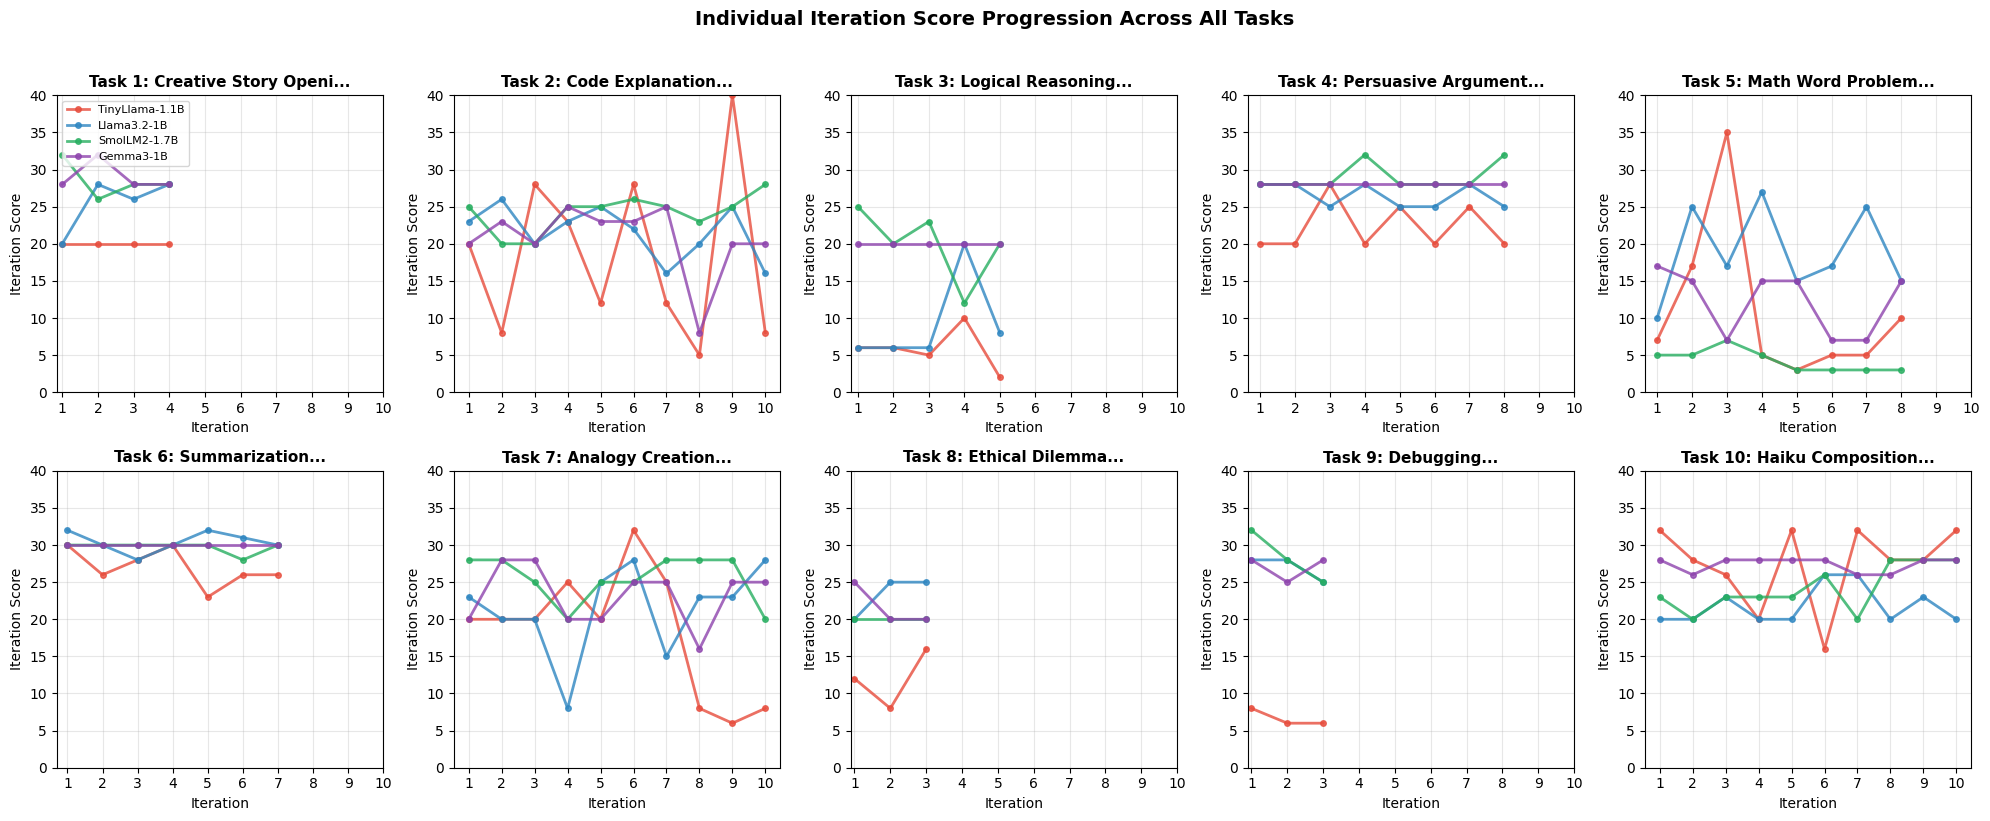

Saved: plots/score_progression_all_tasks.png


In [11]:
"""## Step 10: Visualization - Score Progression Over Iterations

Visualize how each contestant's score evolves during the competition.
"""

# Plot 1: Individual iteration score progression for each task
n_tasks = len(competition_results.task_results)
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

# Unique colors for each contestant (maximally distinct palette)
colors = {
    'TinyLlama-1.1B': '#E74C3C',  # Red
    'Llama3.2-1B': '#2E86C1',     # Blue
    'SmolLM2-1.7B': '#27AE60',    # Green
    'Gemma3-1B': '#8E44AD'        # Purple
}

for idx, task_result in enumerate(competition_results.task_results):
    ax = axes[idx]
    task = task_result.task

    for round_result in task_result.rounds:
        iterations = list(range(1, len(round_result.iterations) + 1))

        for contestant in CONTESTANT_MODELS.keys():
            scores = [
                iter_result.scores.get(contestant, 0)
                for iter_result in round_result.iterations
            ]
            ax.plot(iterations, scores, marker='o', markersize=4,
                   label=contestant, color=colors.get(contestant, 'gray'),
                   linewidth=2, alpha=0.8)

    ax.set_xlabel('Iteration', fontsize=10)
    ax.set_ylabel('Iteration Score', fontsize=10)
    ax.set_title(f'Task {task.id}: {task.name[:20]}...', fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.set_xticks(range(1, T_ITERATIONS + 1))
    ax.set_ylim(0, 40)  # Set consistent scale for iteration scores (0-40)

    if idx == 0:
        ax.legend(loc='upper left', fontsize=8)

plt.suptitle('Individual Iteration Score Progression Across All Tasks', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('plots/score_progression_all_tasks.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/score_progression_all_tasks.png")

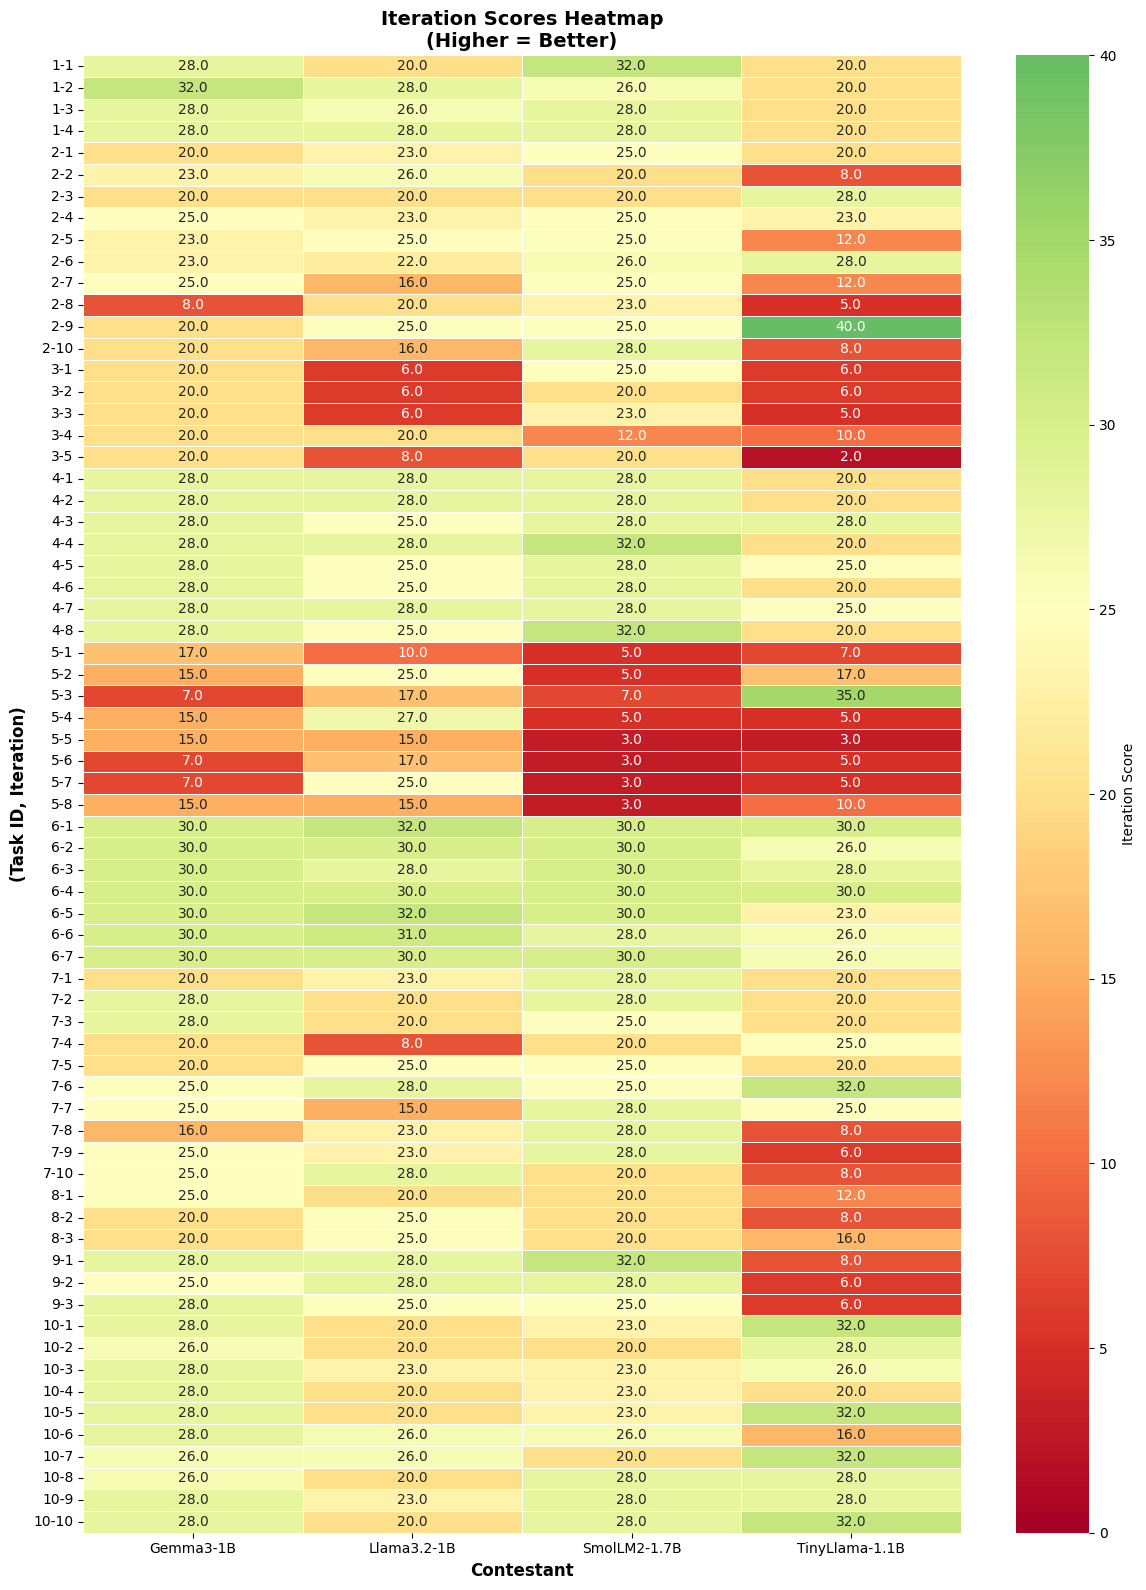

Saved: plots/iteration_scores_heatmap.png


In [12]:




"""## Step 11: Visualization - Per-Iteration Scores Heatmap

Heatmap showing individual iteration scores across tasks and contestants.
"""

# Plot 2: Heatmap of iteration scores
# Create a pivot table for heatmap
pivot_data = iteration_df.pivot_table(
    index=['task_id', 'iteration'],
    columns='contestant',
    values='iteration_score',
    aggfunc='mean'
)

fig, ax = plt.subplots(figsize=(12, 16))
sns.heatmap(pivot_data, annot=True, fmt='.1f', cmap='RdYlGn',
            center=25, vmin=0, vmax=40,
            linewidths=0.5, ax=ax,
            cbar_kws={'label': 'Iteration Score'})

ax.set_xlabel('Contestant', fontsize=12, fontweight='bold')
ax.set_ylabel('(Task ID, Iteration)', fontsize=12, fontweight='bold')
ax.set_title('Iteration Scores Heatmap\n(Higher = Better)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('plots/iteration_scores_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/iteration_scores_heatmap.png")

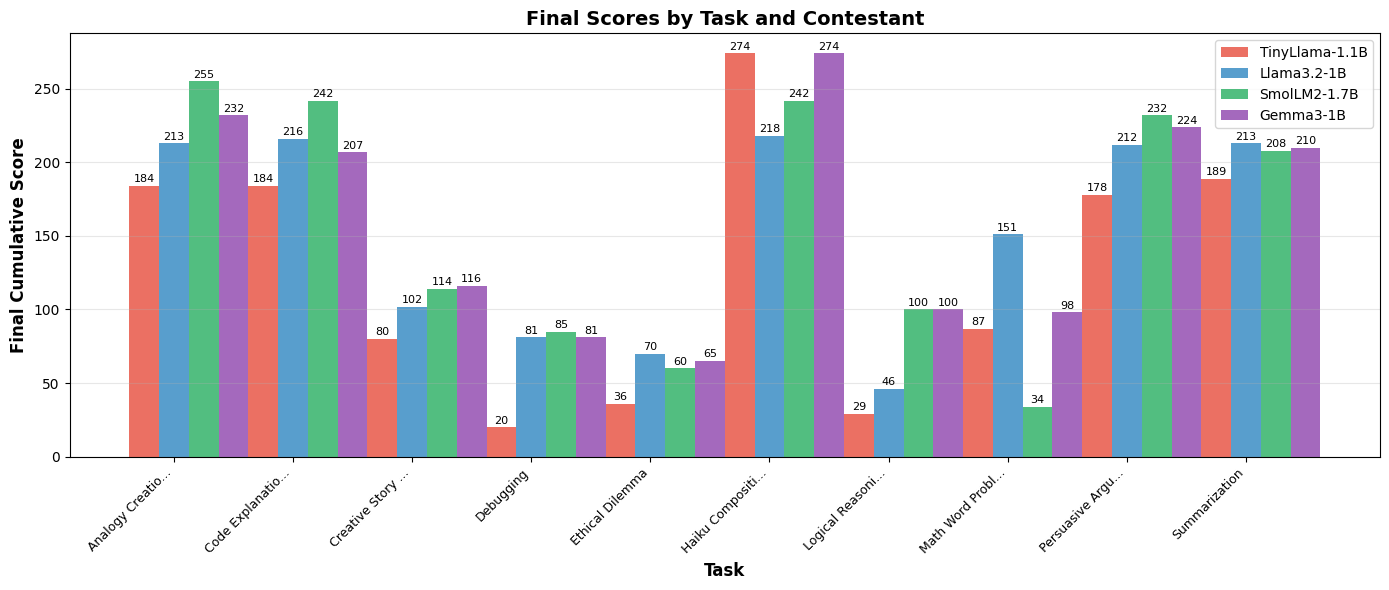

Saved: plots/task_performance_comparison.png


In [13]:


"""## Step 12: Visualization - Task Performance Comparison

Compare how each contestant performed across different task types.
"""

# Plot 3: Bar chart comparing final scores per task
task_scores = iteration_df.groupby(['task_name', 'contestant'])['cumulative_score'].max().reset_index()

fig, ax = plt.subplots(figsize=(14, 6))

task_names = task_scores['task_name'].unique()
x = np.arange(len(task_names))
width = 0.25

for i, contestant in enumerate(CONTESTANT_MODELS.keys()):
    contestant_data = task_scores[task_scores['contestant'] == contestant]
    scores = [contestant_data[contestant_data['task_name'] == t]['cumulative_score'].values[0]
              if len(contestant_data[contestant_data['task_name'] == t]) > 0 else 0
              for t in task_names]
    bars = ax.bar(x + i * width, scores, width, label=contestant,
                  color=colors.get(contestant, 'gray'), alpha=0.8)

    # Add value labels on bars
    for bar, score in zip(bars, scores):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                f'{score:.0f}', ha='center', va='bottom', fontsize=8)

ax.set_xlabel('Task', fontsize=12, fontweight='bold')
ax.set_ylabel('Final Cumulative Score', fontsize=12, fontweight='bold')
ax.set_title('Final Scores by Task and Contestant', fontsize=14, fontweight='bold')
ax.set_xticks(x + width)
ax.set_xticklabels([t[:15] + '...' if len(t) > 15 else t for t in task_names],
                   rotation=45, ha='right', fontsize=9)
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('plots/task_performance_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/task_performance_comparison.png")

/tmp/ipython-input-2852489165.py:47: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-2852489165.py:48: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  plt.savefig('plots/competition_summary.png', dpi=150, bbox_inches='tight')
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


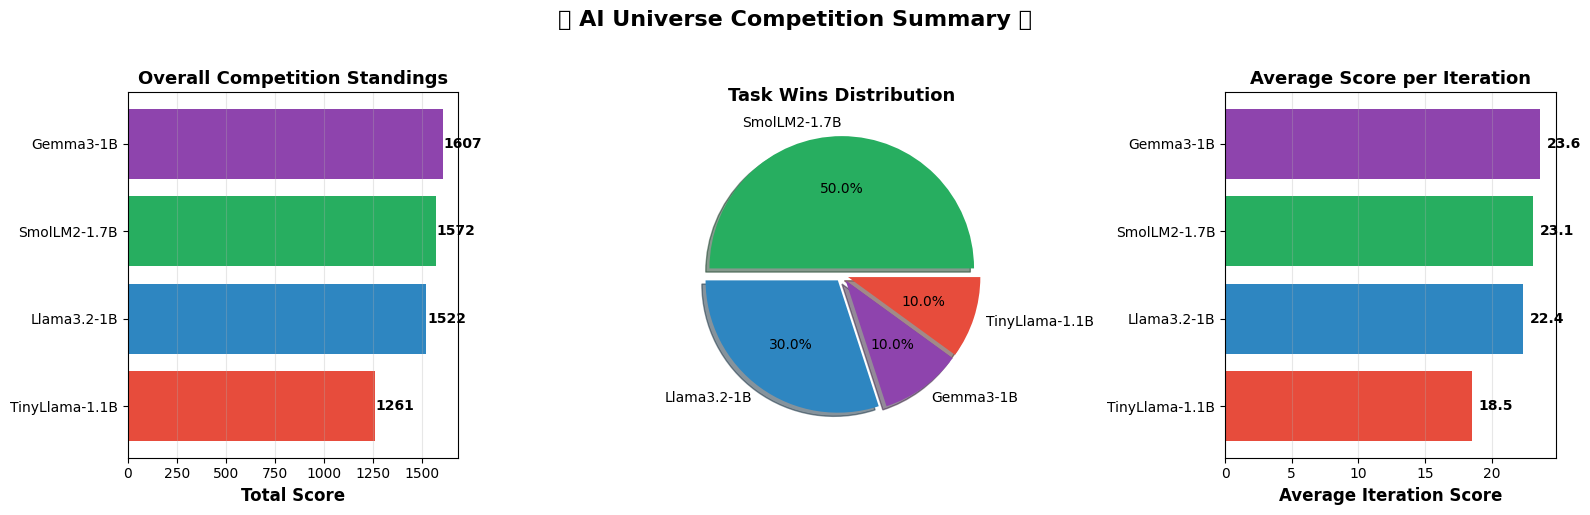

Saved: plots/competition_summary.png


In [14]:


"""## Step 13: Visualization - Overall Competition Summary

Final standings and win distribution.
"""

# Plot 4: Overall standings and statistics
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 4a: Total score bar chart
ax1 = axes[0]
overall_sorted = overall_df.sort_values('total_score', ascending=True)
bars = ax1.barh(overall_sorted['contestant'], overall_sorted['total_score'],
                color=[colors.get(c, 'gray') for c in overall_sorted['contestant']])
ax1.set_xlabel('Total Score', fontsize=12, fontweight='bold')
ax1.set_title('Overall Competition Standings', fontsize=13, fontweight='bold')
for bar, score in zip(bars, overall_sorted['total_score']):
    ax1.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
             f'{score:.0f}', ha='left', va='center', fontweight='bold')
ax1.grid(True, alpha=0.3, axis='x')

# 4b: Win count pie chart
ax2 = axes[1]
win_counts = winners_df['winner'].value_counts()
wedges, texts, autotexts = ax2.pie(
    win_counts.values,
    labels=win_counts.index,
    autopct='%1.1f%%',
    colors=[colors.get(c, 'gray') for c in win_counts.index],
    explode=[0.05] * len(win_counts),
    shadow=True
)
ax2.set_title('Task Wins Distribution', fontsize=13, fontweight='bold')

# 4c: Average score per iteration
ax3 = axes[2]
avg_iter_score = iteration_df.groupby('contestant')['iteration_score'].mean().sort_values(ascending=True)
bars = ax3.barh(avg_iter_score.index, avg_iter_score.values,
                color=[colors.get(c, 'gray') for c in avg_iter_score.index])
ax3.set_xlabel('Average Iteration Score', fontsize=12, fontweight='bold')
ax3.set_title('Average Score per Iteration', fontsize=13, fontweight='bold')
for bar, score in zip(bars, avg_iter_score.values):
    ax3.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             f'{score:.1f}', ha='left', va='center', fontweight='bold')
ax3.grid(True, alpha=0.3, axis='x')

plt.suptitle('🏆 AI Universe Competition Summary 🏆', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('plots/competition_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/competition_summary.png")

/tmp/ipython-input-3353462321.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=iteration_df, x='contestant', y='iteration_score',
/tmp/ipython-input-3353462321.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=iteration_df, x='contestant', y='iteration_score',


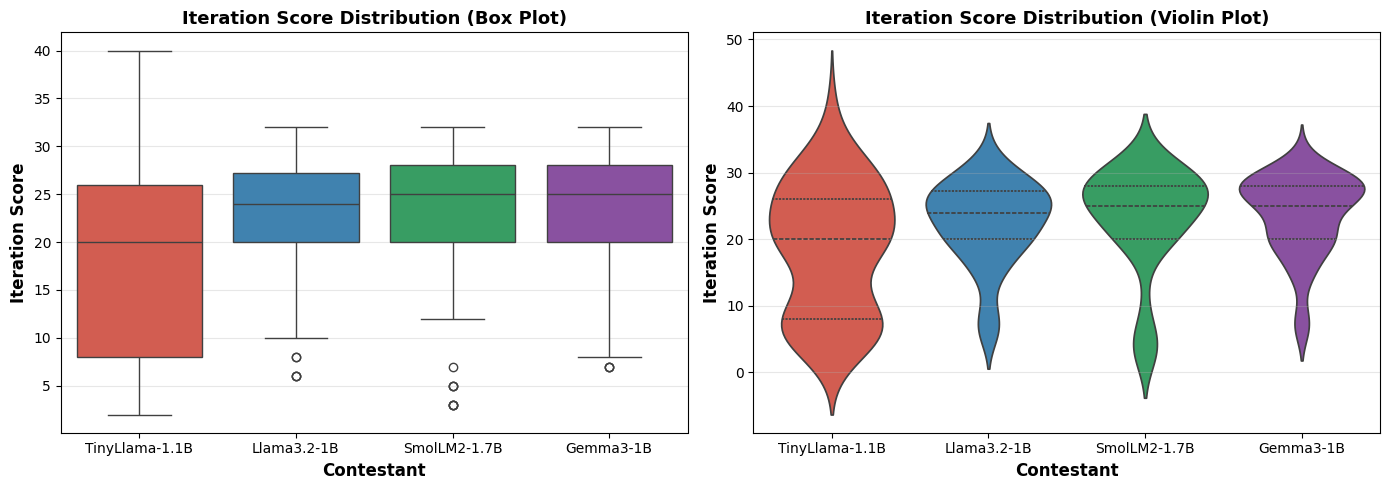

Saved: plots/score_distributions.png


In [15]:


"""## Step 14: Visualization - Score Distribution Analysis

Box plots and violin plots showing score distributions.
"""

# Plot 5: Score distribution analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 5a: Box plot of iteration scores
ax1 = axes[0]
contestant_order = list(CONTESTANT_MODELS.keys())
palette = [colors.get(c, 'gray') for c in contestant_order]
sns.boxplot(data=iteration_df, x='contestant', y='iteration_score',
            order=contestant_order, palette=palette, ax=ax1)
ax1.set_xlabel('Contestant', fontsize=12, fontweight='bold')
ax1.set_ylabel('Iteration Score', fontsize=12, fontweight='bold')
ax1.set_title('Iteration Score Distribution (Box Plot)', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y')

# 5b: Violin plot
ax2 = axes[1]
sns.violinplot(data=iteration_df, x='contestant', y='iteration_score',
               order=contestant_order, palette=palette, ax=ax2, inner='quartile')
ax2.set_xlabel('Contestant', fontsize=12, fontweight='bold')
ax2.set_ylabel('Iteration Score', fontsize=12, fontweight='bold')
ax2.set_title('Iteration Score Distribution (Violin Plot)', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('plots/score_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plots/score_distributions.png")

In [16]:


"""## Step 15: Sample Responses Analysis

Display sample responses from each contestant for a selected task.
"""

# Display sample responses from the first task, first round, last iteration
sample_task_idx = 0  # Change this to view different tasks
sample_round_idx = 0
sample_iter_idx = -1  # Last iteration

if competition_results.task_results:
    task_result = competition_results.task_results[sample_task_idx]
    round_result = task_result.rounds[sample_round_idx]
    iter_result = round_result.iterations[sample_iter_idx]

    print("=" * 80)
    print(f"SAMPLE RESPONSES - Task {task_result.task.id}: {task_result.task.name}")
    print(f"Round {round_result.round_num}, Iteration {iter_result.iteration}")
    print("=" * 80)

    print(f"\nTask Description:\n{task_result.task.description}")
    print("\n" + "-" * 80)

    for contestant, response in iter_result.responses.items():
        score = iter_result.scores.get(contestant, 0)
        print(f"\n{'='*40}")
        print(f"🤖 {contestant} (Score: {score:.1f})")
        print(f"{'='*40}")
        print(response[:1000] + ("..." if len(response) > 1000 else ""))
        print()
else:
    print("No competition results available.")

SAMPLE RESPONSES - Task 1: Creative Story Opening
Round 1, Iteration 4

Task Description:
Write an engaging opening paragraph (3-5 sentences) for a science fiction story 
set on a distant planet where humans have discovered an ancient alien library.

--------------------------------------------------------------------------------

🤖 TinyLlama-1.1B (Score: 20.0)
As the first humans to set foot on the distant planet, we were awestruck by the sight of the sprawling, unfamiliar landscape. But it wasn't long before we realized that this was no ordinary planet.

Standing atop a towering structure, we could see the stars twinkling above us, casting long, ethereal shadows across the sky. The air was thick with the sweet scent of distant plants and the hum of distant machinery.

The library that lay at the heart of this strange new world was unlike anything we had ever seen before. It was a sprawling, multi-level structure, its walls lined with shelves of ancient texts and scrolls.


🤖 Llama3.2

In [17]:


"""## Step 16: Early Termination Analysis

Analyze which tasks had early terminations due to consecutive last places.
"""

# Analyze early terminations
early_terminations = []
warnings_given = []

for task_result in competition_results.task_results:
    for round_result in task_result.rounds:
        if round_result.early_termination:
            early_terminations.append({
                'task_id': task_result.task.id,
                'task_name': task_result.task.name,
                'round': round_result.round_num,
                'terminated_by': round_result.terminated_by,
                'iterations_completed': len(round_result.iterations),
            })

        for iter_result in round_result.iterations:
            if iter_result.warning_given:
                warnings_given.append({
                    'task_id': task_result.task.id,
                    'task_name': task_result.task.name,
                    'round': round_result.round_num,
                    'iteration': iter_result.iteration,
                    'warned_contestant': iter_result.warning_given,
                })

print("=" * 60)
print("EARLY TERMINATION ANALYSIS")
print("=" * 60)

if early_terminations:
    print(f"\nEarly Terminations ({len(early_terminations)} total):")
    term_df = pd.DataFrame(early_terminations)
    print(term_df.to_string(index=False))

    # Count by contestant
    term_counts = term_df['terminated_by'].value_counts()
    print(f"\nTerminations by Contestant:")
    for contestant, count in term_counts.items():
        print(f"  {contestant}: {count} times")
else:
    print("\nNo early terminations occurred.")

print("\n" + "-" * 60)

if warnings_given:
    print(f"\nWarnings Given ({len(warnings_given)} total):")
    warn_df = pd.DataFrame(warnings_given)
    print(warn_df.to_string(index=False))
else:
    print("\nNo warnings were given.")

EARLY TERMINATION ANALYSIS

Early Terminations (9 total):
 task_id              task_name  round  terminated_by  iterations_completed
       1 Creative Story Opening      1 TinyLlama-1.1B                     4
       3      Logical Reasoning      1 TinyLlama-1.1B                     5
       4    Persuasive Argument      1 TinyLlama-1.1B                     8
       5      Math Word Problem      1   SmolLM2-1.7B                     8
       6          Summarization      1 TinyLlama-1.1B                     7
       7       Analogy Creation      1 TinyLlama-1.1B                    10
       8        Ethical Dilemma      1 TinyLlama-1.1B                     3
       9              Debugging      1 TinyLlama-1.1B                     3
      10      Haiku Composition      1    Llama3.2-1B                    10

Terminations by Contestant:
  TinyLlama-1.1B: 7 times
  SmolLM2-1.7B: 1 times
  Llama3.2-1B: 1 times

------------------------------------------------------------

Warnings Given (1

In [18]:


"""## Step 17: Final Summary and Cleanup"""

# Print final summary
print("=" * 70)
print("🏆 AI UNIVERSE COMPETITION - FINAL SUMMARY 🏆")
print("=" * 70)

print(f"\nCompetition Configuration:")
print(f"  - Tasks: {len(tasks)}")
print(f"  - Rounds per task: {N_ROUNDS}")
print(f"  - Iterations per round: {T_ITERATIONS}")
print(f"  - Consecutive last for elimination: {K_CONSECUTIVE}")

print(f"\nContestants:")
for name, model_id in CONTESTANT_MODELS.items():
    print(f"  - {name}: {model_id}")
print(f"  - Judge: {JUDGE_MODEL}")

print("\n" + "-" * 70)
print("FINAL STANDINGS")
print("-" * 70)
print(overall_df.to_string(index=False))

print("\n" + "-" * 70)
print("TASK WINNERS")
print("-" * 70)
print(winners_df[['task_id', 'task_name', 'winner', 'winning_score']].to_string(index=False))

# Determine the champion
if not overall_df.empty:
    champion = overall_df.iloc[0]
    print("\n" + "=" * 70)
    print(f"🎉 CHAMPION: {champion['contestant']} with {champion['total_score']:.0f} total points! 🎉")
    print("=" * 70)

print(f"\nResults saved to plots/ directory:")
print("  - iteration_results.csv")
print("  - task_winners.csv")
print("  - overall_standings.csv")
print("  - score_progression_all_tasks.png")
print("  - iteration_scores_heatmap.png")
print("  - task_performance_comparison.png")
print("  - competition_summary.png")
print("  - score_distributions.png")

# Cleanup - unload all models to free memory
model_manager.unload_all()
print("\nAll models unloaded. Competition complete!")

🏆 AI UNIVERSE COMPETITION - FINAL SUMMARY 🏆

Competition Configuration:
  - Tasks: 10
  - Rounds per task: 1
  - Iterations per round: 10
  - Consecutive last for elimination: 3

Contestants:
  - TinyLlama-1.1B: TinyLlama/TinyLlama-1.1B-Chat-v1.0
  - Llama3.2-1B: meta-llama/Llama-3.2-1B-Instruct
  - SmolLM2-1.7B: HuggingFaceTB/SmolLM2-1.7B-Instruct
  - Gemma3-1B: google/gemma-3-1b-it
  - Judge: Qwen/Qwen2.5-3B-Instruct

----------------------------------------------------------------------
FINAL STANDINGS
----------------------------------------------------------------------
    contestant  total_score  rank
     Gemma3-1B       1607.0     1
  SmolLM2-1.7B       1572.0     2
   Llama3.2-1B       1522.0     3
TinyLlama-1.1B       1261.0     4

----------------------------------------------------------------------
TASK WINNERS
----------------------------------------------------------------------
 task_id              task_name         winner  winning_score
       1 Creative Story Openin